# Simulations of the Heisenberg model alone

* Linear sizes of the cluster must be multiples of 3 to be compatible with the $120^\circ$ Néel order.
* Starting a simulation from a $120^\circ$ Néel state (with $\chi=\pm1$) results in small thermal fluctuations around this state throughout the simulation.
* It is possible to arrive at the $120^\circ$ Néel state starting from a randomized state after a sufficiently high number of steps.
* Specific heat can be directly measured as $c_V = \frac{d\langle E\rangle}{dT} = \frac{1}{kT^2} \left[\langle E^2\rangle - \langle E\rangle^2\right]$.
* Idea: Try to suppress domain walls and to speed up convergence towards the $120^\circ$ Néel state by using reweighting with $w(\phi) = e^{\alpha \sum_i(1 - \chi_i^2)}$.

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.observables
using MX2RKKY.visualization: plot_conf

using Random: MersenneTwister
using LinearAlgebra: norm
using Statistics: mean, std

using PyPlot; const plt = PyPlot;

In [2]:
# Cluster size
L1, L2 = 27, 27

# Heisenberg parameters
J = 1.0
# RKKY parameters
V = 0.0
λ = 0.1 # k_F a_0

0.1

## Energy and chirality evolution at low temperature

120° Néel state as initial state ($\chi=-1$)

In [3]:
T = 0.01

n_mcs = 200000
n_warmup_mcs = 0

conf = Configuration(L1, L2, -1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

Running MC simulation 100%|██████████████████████████████| Time: 0:05:32m


acceptance_rate = 0.02940286694101509


0.02940286694101509

min_energy(sim) / (L1 * L2) = -1.4999293530139282
avg_energy(sim) / (L1 * L2) = -1.4949958184697243
var_energy(sim) / (L1 * L2) = 0.00027179280936553307
specific_heat(sim) / (L1 * L2) = 0.538519310250122
avg_chirality(sim) = -1.0
var_chirality(sim) = 0.0
susc_chirality(sim) / (L1 * L2) = 0.0
binder_chirality(sim) = 0.75
corr_length_chirality(sim) = 1.1450027047409694e17 + 0.0im
susc_spin_K(sim) / (L1 * L2) = 0.5052881496649342
binder_spin_K(sim) = 0.9999991028945514
corr_length_spin_K(sim) = 283.36445088444214 + 0.0im


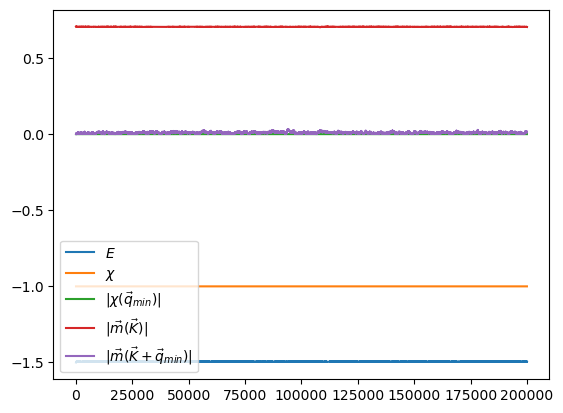

283.36445088444214 + 0.0im

In [4]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

120° Néel state as initial state ($\chi=1$)

In [5]:
T = 0.01

n_mcs = 200000
n_warmup_mcs = 0

conf = Configuration(L1, L2, 1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

Running MC simulation 100%|██████████████████████████████| Time: 0:05:39


acceptance_rate = 0.029376268861454048


0.029376268861454048

min_energy(sim) / (L1 * L2) = -1.4999751764657254
avg_energy(sim) / (L1 * L2) = -1.4949940716591588
var_energy(sim) / (L1 * L2) = 0.0002646557231717015
specific_heat(sim) / (L1 * L2) = 0.5106083775355655
avg_chirality(sim) = 1.0
var_chirality(sim) = 0.0
susc_chirality(sim) / (L1 * L2) = 0.0
binder_chirality(sim) = 0.75
corr_length_chirality(sim) = 1.1432469172363315e17 + 0.0im
susc_spin_K(sim) / (L1 * L2) = 0.22077978109033003
binder_spin_K(sim) = 0.9999989955230386
corr_length_spin_K(sim) = 292.7692622235879 + 0.0im


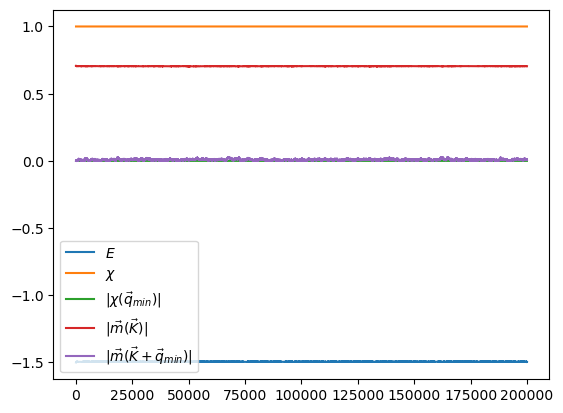

292.7692622235879 + 0.0im

In [6]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

Random initial state

In [7]:
T = 0.01

n_mcs = 200000
n_warmup_mcs = 0

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng)
sim = MCSimulation(conf, rng, β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

Running MC simulation 100%|██████████████████████████████| Time: 0:05:46


acceptance_rate = 0.031031213991769547


0.031031213991769547

min_energy(sim) / (L1 * L2) = -1.3924221053792454
avg_energy(sim) / (L1 * L2) = -1.3873272257385558
var_energy(sim) / (L1 * L2) = 0.0076654715238719
specific_heat(sim) / (L1 * L2) = 428.3542755674392
avg_chirality(sim) = 0.07520908093278471
var_chirality(sim) = 0.01670146340979743
susc_chirality(sim) / (L1 * L2) = 0.027893748533438893
binder_chirality(sim) = 0.6307936255043274
susc_spin_K(sim) / (L1 * L2) = 0.2503619361008999
binder_spin_K(sim) = 0.9901180923517483
corr_length_spin_K(sim) = 6.369827359667853 + 0.0im


sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


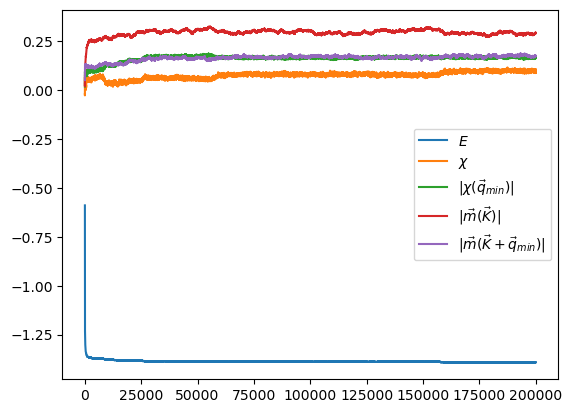

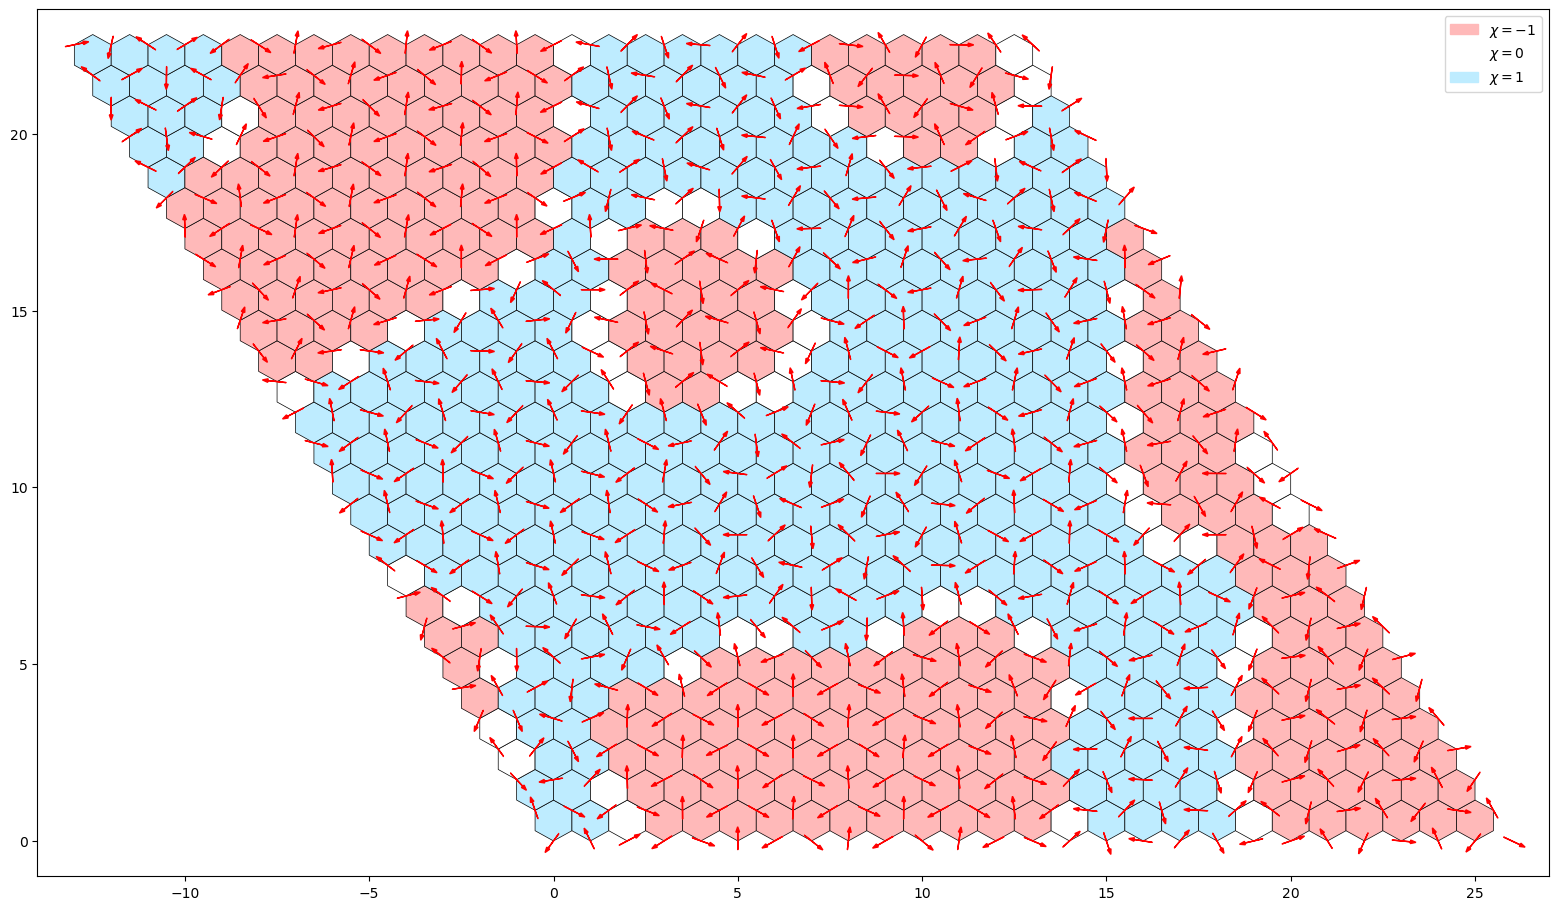

In [8]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show specific_heat(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show susc_chirality(sim) / (L1 * L2)
@show binder_chirality(sim)
#@show corr_length_chirality(sim)
@show susc_spin_K(sim) / (L1 * L2)
@show binder_spin_K(sim)
@show corr_length_spin_K(sim)

fig = plot_conf(sim.conf);
fig.savefig("heisenberg_conf_T0.01.pdf")

In [9]:
@show min_energy(sim)
@show avg_energy(sim, 100000:200000) / (L1 * L2)
@show var_energy(sim, 100000:200000) / (L1 * L2)
@show specific_heat(sim, 100000:200000) / (L1 * L2)
@show avg_chirality(sim, 100000:200000)
@show var_chirality(sim, 100000:200000)
@show susc_chirality(sim, 100000:200000) / (L1 * L2)
@show binder_chirality(sim, 100000:200000)
#@show corr_length_chirality(sim, 100000:200000)
@show susc_spin_K(sim, 100000:200000) / (L1 * L2)
@show binder_spin_K(sim, 100000:200000)
@show corr_length_spin_K(sim, 100000:200000)

min_energy(sim) = -1015.0757148214699
avg_energy(sim, 100000:200000) / (L1 * L2) = -1.3899434191831526
var_energy(sim, 100000:200000) / (L1 * L2) = 0.0012721726785377722
specific_heat(sim, 100000:200000) / (L1 * L2) = 11.798188051040219
avg_chirality(sim, 100000:200000) = 0.08579283205796213
var_chirality(sim, 100000:200000) = 0.01009759072507883
susc_chirality(sim, 100000:200000) / (L1 * L2) = 0.010196031884798437
binder_chirality(sim, 100000:200000) = 0.7084132839221575
susc_spin_K(sim, 100000:200000) / (L1 * L2) = 0.19074825216577607
binder_spin_K(sim, 100000:200000) = 0.9959066621614576
corr_length_spin_K(sim, 100000:200000) = 6.0524458478096035 + 0.0im


6.0524458478096035 + 0.0im

Random initial state, higher temperature

In [10]:
T = 0.1

n_mcs = 250000
n_warmup_mcs = 0

# seed = 127459: Fully polarized solution after ~200000 cycles
rng = MersenneTwister(127459)
conf = Configuration(L1, L2, rng)
sim = MCSimulation(conf, rng, β=1/T, J=J, V=V, λ=λ)
acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
@show acceptance_rate

Running MC simulation 100%|██████████████████████████████| Time: 0:07:58


acceptance_rate = 0.09517313031550069


0.09517313031550069

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


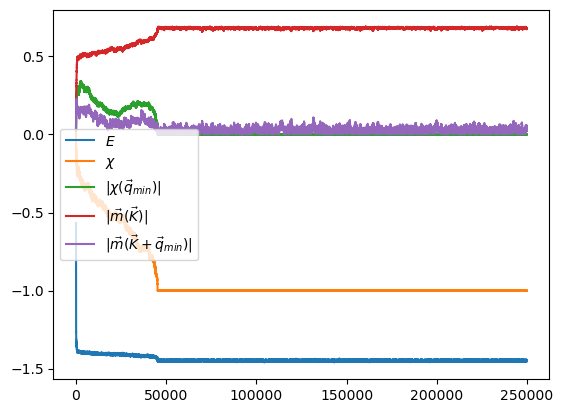

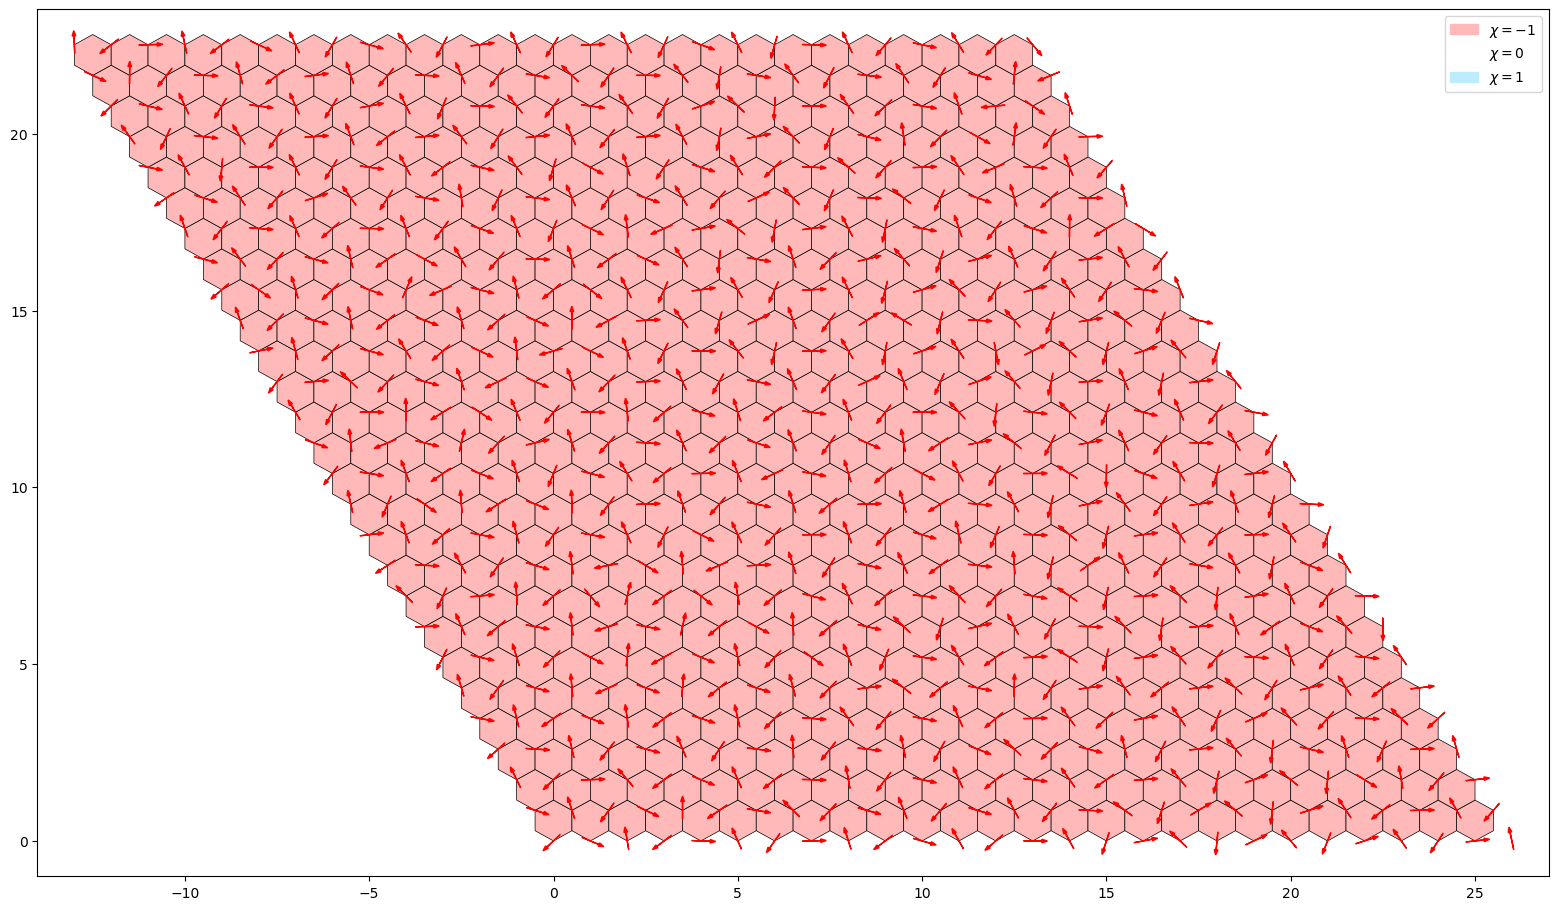

In [11]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.plot(abs.(sim.measurements.chirality_at_q_min), label=raw"$|\chi(\vec{q}_{min})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K, dims=2)), label=raw"$|\vec{m}(\vec{K})|$")
plt.plot(map(norm, eachslice(sim.measurements.magnetization_at_K_q_min, dims=2)), label=raw"$|\vec{m}(\vec{K}+\vec{q}_{min})|$")
plt.legend()

fig = plot_conf(sim.conf);
fig.savefig("heisenberg_conf_T0.1.pdf")

In [12]:
@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim, 200000:250000) / (L1 * L2)
@show var_energy(sim, 200000:250000) / (L1 * L2)
@show specific_heat(sim, 100000:200000) / (L1 * L2)
@show avg_chirality(sim, 200000:250000)
@show var_chirality(sim, 200000:250000)
@show susc_chirality(sim, 200000:250000) / (L1 * L2)
@show binder_chirality(sim, 200000:250000)
@show corr_length_chirality(sim, 200000:250000)
@show susc_spin_K(sim, 200000:250000) / (L1 * L2)
@show binder_spin_K(sim, 200000:250000)
@show corr_length_spin_K(sim, 200000:250000)

min_energy(sim) / (L1 * L2) = -1.4603908632699694
avg_energy(sim, 200000:250000) / (L1 * L2) = -1.4487410290552862
var_energy(sim, 200000:250000) / (L1 * L2) = 0.00267704044832648
specific_heat(sim, 100000:200000) / (L1 * L2) = 0.5323740910797473
avg_chirality(sim, 200000:250000) = -0.9999356117130052
var_chirality(sim, 200000:250000) = 0.00030046062719603014
susc_chirality(sim, 200000:250000) / (L1 * L2) = 9.027478431455904e-7
binder_chirality(sim, 200000:250000) = 0.7499997295310052
corr_length_chirality(sim, 200000:250000) = 14411.83223166123 + 0.0im
susc_spin_K(sim, 200000:250000) / (L1 * L2) = 0.5967959698911962
binder_spin_K(sim, 200000:250000) = 0.9998974174589972
corr_length_spin_K(sim, 200000:250000) = 87.36536891642307 + 0.0im


87.36536891642307 + 0.0im

## Temperature scan

In [13]:
# Cluster size
L1, L2 = 27, 27

# Heisenberg parameter
J = 1.0
# RKKY parameters
V = 0.0
λ = 0.1

# Temperature range
T_range = 0.05:0.05:2.0

n_mcs = 50000 #200000
n_warmup_mcs = 0

E = zeros(n_mcs, length(T_range))
χ = zeros(n_mcs, length(T_range))
χ_at_q_min = zeros(ComplexF64, n_mcs, length(T_range))
m_at_K = zeros(ComplexF64, 2, n_mcs, length(T_range))
m_at_K_q_min = zeros(ComplexF64, 2, n_mcs, length(T_range))

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, -1)

for (n, T) in enumerate(T_range)
    @show T
    sim = MCSimulation(conf, rng, β=1/T, J=J, V=V, λ=λ)
    acceptance_rate = run!(sim, n_mcs=n_mcs, n_warmup_mcs=n_warmup_mcs)
    @show acceptance_rate

    E[:, n] = sim.measurements.energy
    χ[:, n] = sim.measurements.chirality
    χ_at_q_min[:, n] = sim.measurements.chirality_at_q_min
    m_at_K[:, :, n] = sim.measurements.magnetization_at_K
    m_at_K_q_min[:, :, n] = sim.measurements.magnetization_at_K_q_min

    conf = deepcopy(sim.conf)
end

write("heisenberg_T_scan_E.dat", E)
write("heisenberg_T_scan_chi.dat", χ)
write("heisenberg_T_scan_chi_at_q_min.dat", χ_at_q_min)
write("heisenberg_T_scan_m_at_K.dat", m_at_K)
write("heisenberg_T_scan_m_at_K_q_min.dat", m_at_K_q_min)

T = 0.05


Running MC simulation 100%|██████████████████████████████| Time: 0:01:34


acceptance_rate = 0.06622145404663923
T = 0.1


Running MC simulation 100%|██████████████████████████████| Time: 0:01:41


acceptance_rate = 0.09464417009602195
T = 0.15


Running MC simulation 100%|██████████████████████████████| Time: 0:01:42


... (72 outputs left out)

acceptance_rate = 0.6541267215363512
T = 2.0


Running MC simulation 100%|██████████████████████████████| Time: 0:02:38


acceptance_rate = 0.6606010425240055


64000000

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


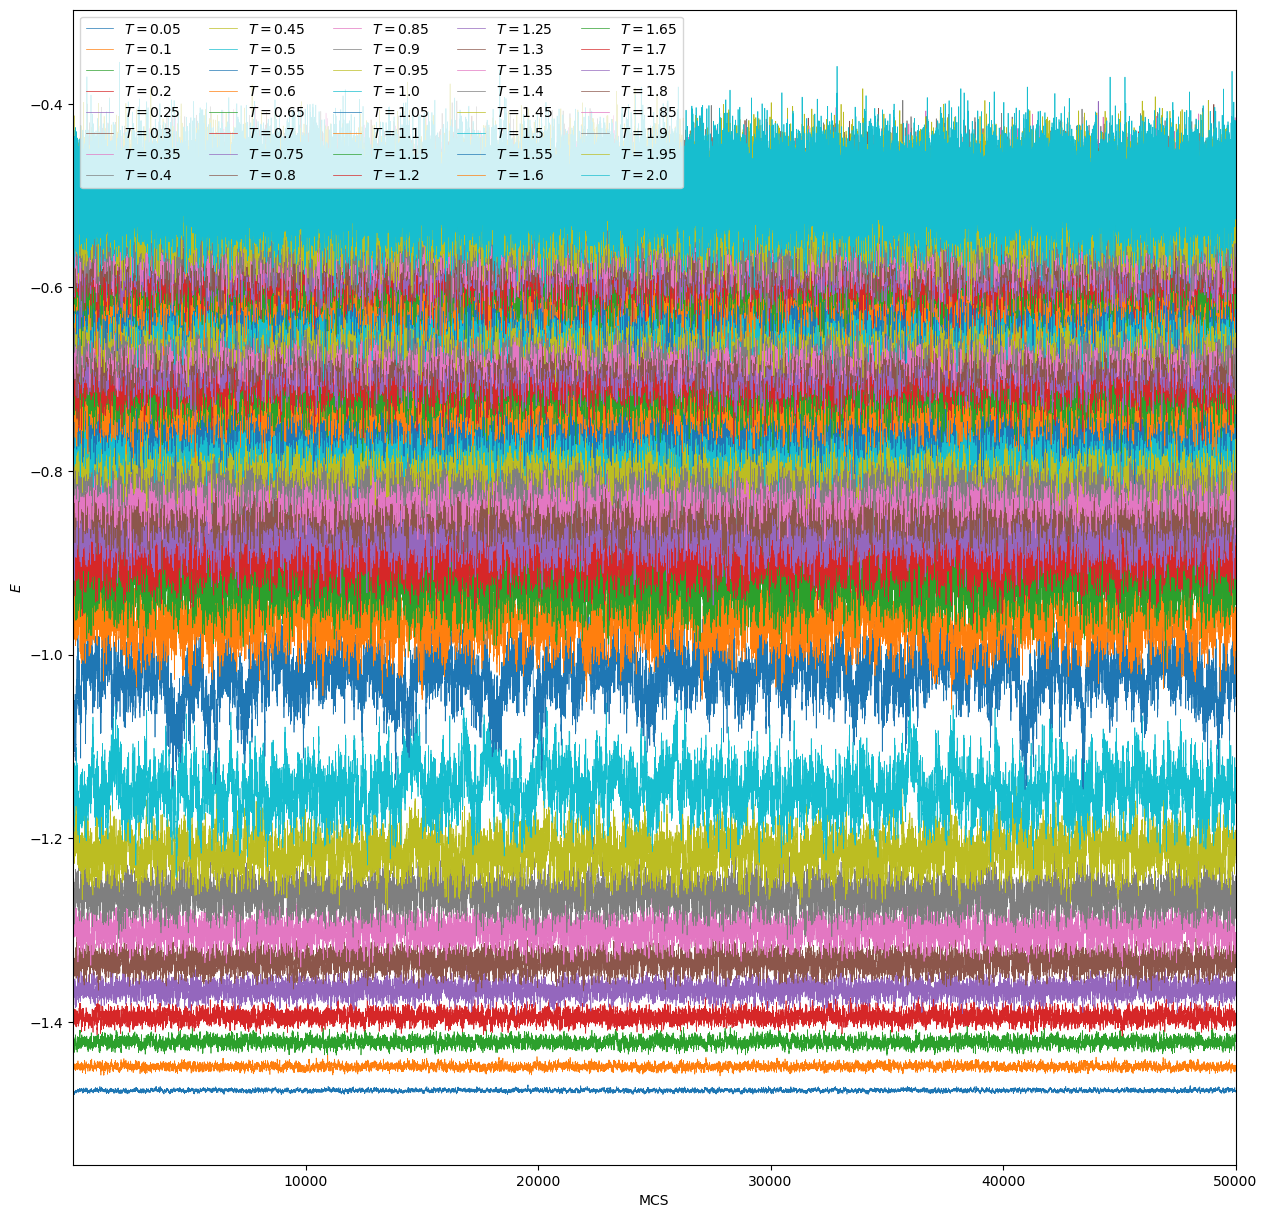

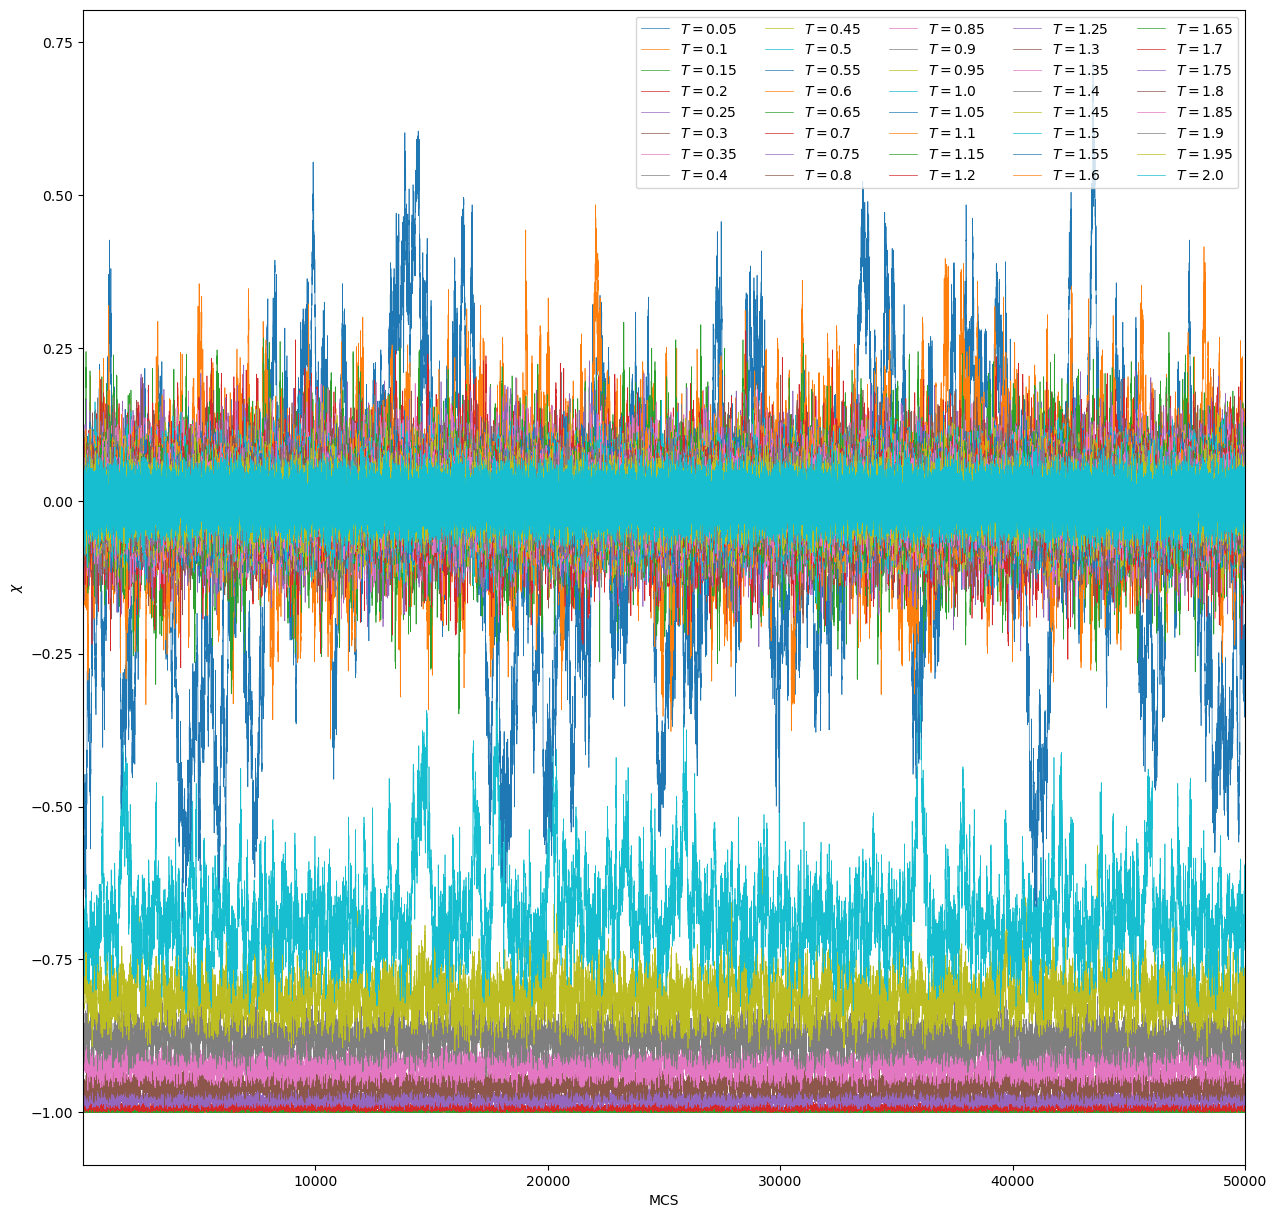

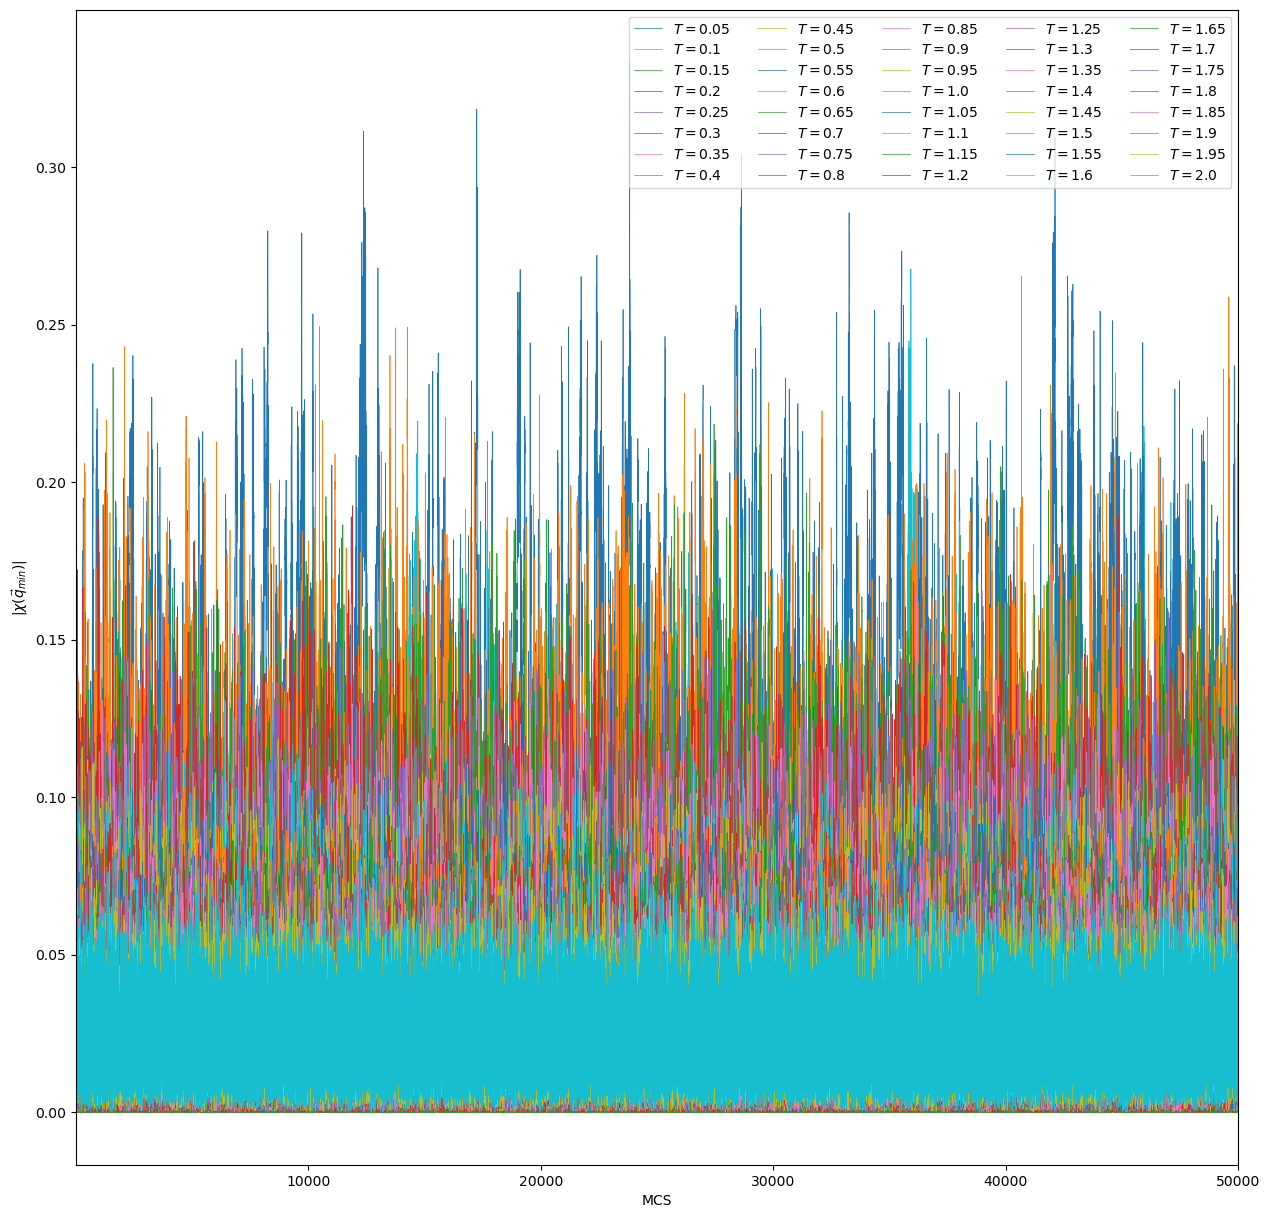

In [14]:
plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(E[:, n] / (L1 * L2), label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_mcs))
plt.xlabel("MCS")
plt.ylabel(raw"$E$")
plt.legend(loc="best", ncol=5)
plt.show()

plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(χ[:, n], label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_mcs))
plt.xlabel("MCS")
plt.ylabel(raw"$\chi$")
plt.legend(loc="best", ncol=5)
plt.show()

plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(abs.(χ_at_q_min[:, n]), label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_mcs))
plt.xlabel("MCS")
plt.ylabel(raw"$|\chi(\vec{q}_{min})|$")
plt.legend(loc="best", ncol=5)
plt.show()

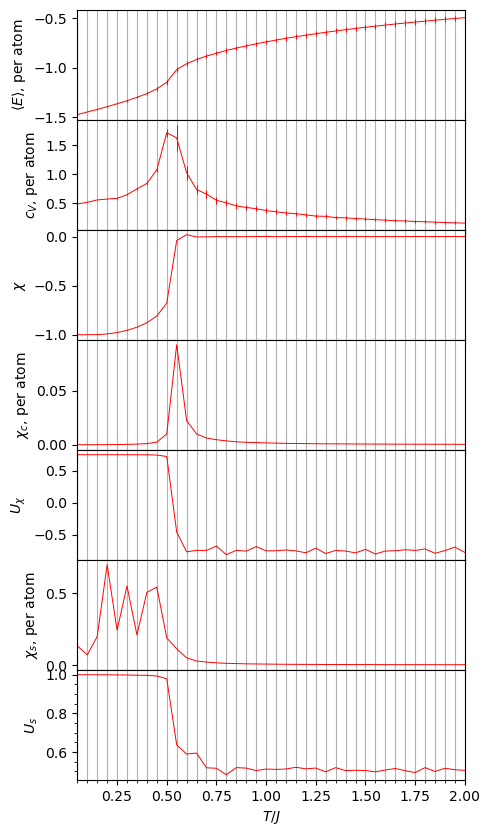

In [15]:
first_cycle = 25_000 #100_000
last_cycle = 50_000 #200_000

E_avg = [avg_energy(E[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
E_var = [var_energy(E[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
cV = [specific_heat(E[:, n], 1.0 / T_range[n], first_cycle:last_cycle) for n in 1:length(T_range)]

χ_avg = [avg_chirality(χ[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
χ_var = [var_chirality(χ[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
χ_susc = [susc_chirality(χ[:, n], L1 * L2, 1.0 / T_range[n], first_cycle:last_cycle) for n in 1:length(T_range)]
χ_binder = [binder_chirality(χ[:, n], first_cycle:last_cycle) for n in 1:length(T_range)]
#χ_cl = [corr_length_chirality(χ[:, n], χ_at_q_min[:, n], L1, first_cycle:last_cycle) for n in 1:length(T_range)]

m_susc = [susc_spin_K(m_at_K[:, :, n], L1 * L2, 1.0 / T_range[n], first_cycle:last_cycle) for n in 1:length(T_range)]
m_binder = [binder_spin_K(m_at_K[:, :, n], first_cycle:last_cycle) for n in 1:length(T_range)]
m_cl = [corr_length_spin_K(m_at_K[:, :, n], m_at_K_q_min[:, :, n], L1, first_cycle:last_cycle) for n in 1:length(T_range)]

plt.figure(figsize=(5, 10))
gs = plt.matplotlib.gridspec.GridSpec(7, 1, hspace=0)

ax1 = plt.subplot(gs[1])
ax1.errorbar(collect(T_range), E_avg / (L1 * L2), yerr=E_var / (L1 * L2), lw=0.7, color="red")
ax1.set_ylabel(raw"$\langle E\rangle$, per atom")
plt.setp(ax1.get_xticklabels(), visible=false)
ax1.grid(axis="x", which="both")

ax2 = plt.subplot(gs[2], sharex=ax1)
ax2.errorbar(collect(T_range), cV / (L1 * L2), yerr=χ_var, lw=0.7, color="red")
ax2.set_ylabel(raw"$c_V$, per atom")
plt.setp(ax2.get_xticklabels(), visible=false)
ax2.grid(axis="x", which="both")

ax3 = plt.subplot(gs[3], sharex=ax1)
ax3.plot(collect(T_range), χ_avg, lw=0.7, color="red")
ax3.set_ylabel(raw"$\chi$")
plt.setp(ax3.get_xticklabels(), visible=false)
ax3.grid(axis="x", which="both")

ax4 = plt.subplot(gs[4], sharex=ax1)
ax4.plot(collect(T_range), χ_susc / (L1 * L2), lw=0.7, color="red")
ax4.set_ylabel(raw"$\chi_c$, per atom")
plt.setp(ax4.get_xticklabels(), visible=false)
ax4.grid(axis="x", which="both")

ax5 = plt.subplot(gs[5], sharex=ax1)
ax5.plot(collect(T_range), χ_binder, lw=0.7, color="red")
ax5.set_ylabel(raw"$U_\chi$")
plt.setp(ax5.get_xticklabels(), visible=false)
ax5.grid(axis="x", which="both")

ax6 = plt.subplot(gs[6], sharex=ax1)
ax6.plot(collect(T_range), m_susc / (L1 * L2), lw=0.7, color="red")
ax6.set_ylabel(raw"$\chi_s$, per atom")
plt.setp(ax6.get_xticklabels(), visible=false)
ax6.grid(axis="x", which="both")

ax7 = plt.subplot(gs[7], sharex=ax1)
ax7.plot(collect(T_range), m_binder, lw=0.7, color="red")
ax7.set_ylabel(raw"$U_s$")
ax7.grid(axis="x", which="both")

ax7.set_xlim((first(T_range), last(T_range)))
ax7.set_xlabel(raw"$T/J$")
ax7.minorticks_on()
plt.show()